# Notebook 1: Data and Geo-analysis

HST-105 Analytics for Business and Society

Team: Aashit Kumar Singh, Bhaskar Bhushan, Dhruv Singh Bisht

In this notebook we clean the CPCB PM2.5 data, pick a small set of stations across the Indo-Gangetic Plain and add daily weather. Then we look at how pollution is spread over the plain: seasonal maps, how similarity changes with distance, whether pollution moves from Delhi to the east, and which stations form airsheds. At the end we save one station-day table for Notebooks 2 and 3.

## Setup
Here we import the libraries and set the folders, colours and plot style. We also write a few helper functions that we use many times. The raw files in data/ are only read; we save only into data/processed/ and figures_outputs/.

In [ ]:
# Import the libraries we need and set paths, colours and plot style
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import requests
from scipy.optimize import curve_fit
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

try:
    import geopandas as gpd
except ImportError:
    gpd = None
    print('geopandas is not installed: maps will be drawn without state borders.')

np.random.seed(42)

# Folders (the notebook runs from inside notebooks/)
datadir = '../data/'
procdir = '../data/processed/'
figdir = '../figures_outputs/'
os.makedirs(procdir, exist_ok=True)
os.makedirs(figdir, exist_ok=True)

# Our muted palette (same as the paper)
teal = '#005468'
orange = '#BA6A3E'
slate = '#344054'
green = '#427A5A'
plum = '#74547C'
grey = '#9AA3AF'

# Plot style: white background, light grid, readable font, no top/right spines
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linewidth': 0.6,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
# Helper functions: safe saving, name cleaning, finding columns, distance
def checkpath(path):
    # Only allow saving inside data/processed/ or figures_outputs/
    full = os.path.abspath(path)
    allowed = False
    for folder in [procdir, figdir]:
        if full.startswith(os.path.abspath(folder) + os.sep):
            allowed = True
    if not allowed:
        raise ValueError('Refusing to save outside data/processed/ or figures_outputs/: ' + path)


def savecsv(table, path):
    # Write to a temporary file first, then replace the real file in one step
    checkpath(path)
    tmp = path + '.tmp'
    table.to_csv(tmp, index=False)
    os.replace(tmp, path)
    print('Saved', path)


def savegeo(frame, path):
    # Same idea as savecsv, for map files
    checkpath(path)
    tmp = path + '.tmp'
    if os.path.exists(tmp):
        os.remove(tmp)
    frame.to_file(tmp, driver='GeoJSON')
    os.replace(tmp, path)
    print('Saved', path)


aliases = {'allahabad': 'prayagraj', 'gurgaon': 'gurugram', 'calcutta': 'kolkata'}


def cleanname(name):
    # Lowercase, strip spaces and replace old city names by new ones
    name = str(name).lower().strip()
    name = ' '.join(name.split())
    if name in aliases:
        name = aliases[name]
    return name


def statekey(name):
    # Make state names comparable: lowercase, '&' -> 'and', 'NCT of Delhi' -> 'delhi'
    name = str(name).lower().strip()
    name = name.replace('&', 'and')
    name = ' '.join(name.split())
    if 'delhi' in name:
        name = 'delhi'
    if name == 'uttaranchal':
        name = 'uttarakhand'
    return name


def findcol(table, options):
    # Return the first column whose name matches one of the options (ignoring case)
    for option in options:
        for col in table.columns:
            if str(col).lower().strip() == option.lower():
                return col
    return None


def haversine(lat1, lon1, lat2, lon2):
    # Great-circle distance in km between two points given in degrees
    r = 6371.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    inside = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(inside))

### Settings
We keep all the numbers we may want to change in this cell, for example the coverage limit for stations or the neighbour radius.

In [3]:
# Settings we may want to change
startdate = '2017-01-01'
enddate = '2024-12-31'
mincoverage = 0.60        # a station needs at least 60% valid days over 2017-2024
percity = 2               # stations kept per city
startbefore = '2018-01-01'  # first data must be before this date (needed for the policy test)
radius = 200              # neighbour radius in km (try 100 or 300 as well)
perrequest = 10           # stations per weather request
pause = 3                 # seconds to wait between weather requests

igp = ['punjab', 'haryana', 'delhi', 'uttar pradesh', 'bihar', 'west bengal']
neighbours = ['rajasthan', 'uttarakhand', 'himachal pradesh', 'jharkhand', 'madhya pradesh',
              'chandigarh', 'jammu and kashmir']
targets = ['Amritsar', 'Ludhiana', 'Jalandhar', 'Patiala', 'Delhi', 'Gurugram', 'Faridabad',
           'Panipat', 'Agra', 'Kanpur', 'Lucknow', 'Varanasi', 'Prayagraj', 'Gorakhpur',
           'Moradabad', 'Patna', 'Gaya', 'Muzaffarpur', 'Kolkata', 'Howrah']

smallpath = procdir + 'states-small.geojson'
weatherpath = procdir + 'weather.csv'
panelpath = procdir + 'panel.csv'

## Step 1: Checking the input files
First we check that the raw files are in data/. If a file in data/processed/ ever looks broken, we can just delete it and run the notebook again; it will be rebuilt from the original data.

In [4]:
# Check that the input files exist and print their size
def checkfiles(files):
    missing = []
    for path, advice in files:
        if os.path.exists(path):
            size = os.path.getsize(path) / 1e6
            print('OK       ', path, '(', round(size, 1), 'MB )')
        else:
            print('MISSING  ', path, '->', advice)
            missing.append(path)
    if len(missing) > 0:
        raise FileNotFoundError('Missing input files: ' + ', '.join(missing))


needed = [(datadir + 'main_data.pkl', 'download main_data.pkl (VayuBench) into the data/ folder')]
if os.path.exists(smallpath):
    needed.append((smallpath, ''))
else:
    needed.append((datadir + 'india_states.geojson', 'download india_states.geojson into the data/ folder'))
checkfiles(needed)

OK        ../data/main_data.pkl ( 100.4 MB )
OK        ../data/processed/states-small.geojson ( 0.4 MB )


## Step 2: Loading the station data
Now we load main_data.pkl. It has one row per station per day for stations all over India.

In [5]:
# Load the CPCB station data (read only) and look at it
raw = pd.read_pickle(datadir + 'main_data.pkl')
print('Shape:', raw.shape)
print('Columns:', list(raw.columns))
raw.head(3)

Shape: (1627461, 9)
Columns: ['Timestamp', 'station', 'PM2.5', 'PM10', 'address', 'city', 'latitude', 'longitude', 'state']


,Timestamp,station,PM2.5,PM10,address,city,latitude,longitude,state
0,2017-01-01,"32Bungalows, Bhilai - CECB",NaN,NaN,"Bhilai RO Office, 5, 32 Bungalows, Bhilai, Dis...",Bhilai,21.194815,81.314770,Chhattisgarh
1,2017-01-01,"AIIMS, Raipur - CECB",NaN,NaN,"All India Institute Of Medical Science, Gate N...",Raipur,21.258815,81.578979,Chhattisgarh
2,2017-01-01,"Adarsh Nagar, Jaipur - RSPCB",NaN,NaN,"Psychiatric Centre, Janta Colony, Govind Marg,...",Jaipur,26.902909,75.836858,Rajasthan


We give the columns short names: date, station, pm (PM2.5 in µg/m³), city, state, lat and lon.

In [6]:
# Find the columns we need and give them simple names
wanted = {
    'date': ['Timestamp', 'date', 'datetime'],
    'station': ['station'],
    'pm': ['PM2.5', 'pm25', 'pm2.5', 'pm'],
    'city': ['city'],
    'state': ['state'],
    'lat': ['latitude', 'lat'],
    'lon': ['longitude', 'lon', 'lng'],
}
found = {}
for newname, options in wanted.items():
    col = findcol(raw, options)
    if col is None:
        raise KeyError('Could not find a column for ' + newname + '. Columns are: ' + str(list(raw.columns)))
    found[col] = newname
    print(newname, '<-', col)

data = raw[list(found.keys())].rename(columns=found)
del raw
data['date'] = pd.to_datetime(data['date']).dt.normalize()
print(data.dtypes)

date <- Timestamp
station <- station
pm <- PM2.5
city <- city
state <- state
lat <- latitude
lon <- longitude
date       datetime64[ns]
station            object
pm                float64
city               object
state              object
lat               float64
lon               float64
dtype: object


### Keeping only the IGP states
We keep only Punjab, Haryana, Delhi, Uttar Pradesh, Bihar and West Bengal, and only the years 2017 to 2024. We also clean the city names, for example Allahabad becomes Prayagraj.

In [7]:
# Keep only the six IGP states and the years 2017-2024
print('State names in the data:')
print(sorted(data['state'].dropna().unique()))

keymap = {}
for name in data['state'].dropna().unique():
    keymap[name] = statekey(name)
keys = data['state'].map(keymap)
for name in igp:
    if name not in set(keymap.values()):
        print('Not found in the data:', name)

data = data[keys.isin(igp)].copy()
data = data[(data['date'] >= startdate) & (data['date'] <= enddate)]

citymap = {}
for name in data['city'].dropna().unique():
    citymap[name] = cleanname(name).title()
data['city'] = data['city'].map(citymap)
data = data.drop_duplicates(['station', 'date'])

print('IGP states kept:', sorted(data['state'].unique()))
print('Rows:', len(data), '  Stations:', data['station'].nunique())

State names in the data:
['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
IGP states kept: ['Bihar', 'Delhi', 'Haryana', 'Punjab', 'Uttar Pradesh', 'West Bengal']
Rows: 534819   Stations: 193


## Step 3: Cleaning the data
We use our four cleaning rules. Values of zero or below are dropped, values above 999 are set to missing, and a value that stays exactly the same for 3 or more days in a row is treated as a stuck sensor. The fourth rule, coverage, is used when we choose the stations.

In [8]:
# Rules 1 and 2: drop values <= 0 and set values > 999 to missing
bad = data['pm'] <= 0
data = data[~bad].copy()
print('Rule 1: dropped', int(bad.sum()), 'rows with PM2.5 <= 0')

toohigh = data['pm'] > 999
data.loc[toohigh, 'pm'] = np.nan
print('Rule 2: set', int(toohigh.sum()), 'values above 999 to missing')

Rule 1: dropped 0 rows with PM2.5 <= 0
Rule 2: set 9 values above 999 to missing


In [9]:
# Rule 3: find runs of the same value on 3+ consecutive days at one station
data = data.sort_values(['station', 'date']).reset_index(drop=True)
prevval = data.groupby('station')['pm'].shift(1)
prevdate = data.groupby('station')['date'].shift(1)
gapdays = (data['date'] - prevdate).dt.days

# A new run starts when the value changes or the days are not consecutive
newrun = (data['pm'] != prevval) | (gapdays != 1)
runid = newrun.cumsum()
runlen = data.groupby(runid)['pm'].transform('size')
stuck = (runlen >= 3) & data['pm'].notna()
data.loc[stuck, 'pm'] = np.nan
print('Rule 3: set', int(stuck.sum()), 'stuck values to missing')

Rule 3: set 120 stuck values to missing


## Step 4: Choosing the stations
To keep the notebooks fast we keep at most two stations per city, but from many cities between Punjab and West Bengal. A station must have at least 60% valid days and data from before 2018, because Notebook 3 needs some time before NCAP started.

In [10]:
# Count valid days and the first date with data for every station
totaldays = (pd.Timestamp(enddate) - pd.Timestamp(startdate)).days + 1
valid = data[data['pm'].notna()]
summary = valid.groupby('station').agg(
    city=('city', 'first'),
    state=('state', 'first'),
    lat=('lat', 'median'),
    lon=('lon', 'median'),
    validdays=('pm', 'count'),
    firstdate=('date', 'min'),
)
summary['coverage'] = summary['validdays'] / totaldays

# Pick the best stations in each target city
chosen = []
for city in targets:
    rows = summary[summary['city'] == city]
    if len(rows) == 0:
        print('Skipped', city, ': no stations with this city name in the data')
        continue
    good = rows[(rows['coverage'] >= mincoverage) & (rows['firstdate'] < startbefore)]
    if len(good) == 0:
        print('Skipped', city, ':', len(rows), 'stations, but none has enough coverage and early data')
        continue
    good = good.sort_values('validdays', ascending=False).head(percity)
    chosen.append(good)

if len(chosen) == 0:
    raise ValueError('No station passed the rules. Try a lower mincoverage in the Settings cell.')
stations = pd.concat(chosen)
stations.index.name = 'station'
names = list(stations.index)
data = data[data['station'].isin(names)].copy()

# City centre = mean position of its selected stations
centres = stations.groupby('city')[['lat', 'lon']].mean()

print('Selected', len(stations), 'stations in', stations['city'].nunique(), 'cities')
table = stations[['city', 'state', 'lat', 'lon', 'validdays', 'firstdate', 'coverage']].reset_index()
table['coverage'] = table['coverage'].round(3)
savecsv(table, figdir + 'nb1-stations.csv')
table

Skipped Jalandhar : 1 stations, but none has enough coverage and early data
Skipped Patiala : 1 stations, but none has enough coverage and early data
Skipped Panipat : 1 stations, but none has enough coverage and early data
Skipped Prayagraj : 3 stations, but none has enough coverage and early data
Skipped Gorakhpur : 1 stations, but none has enough coverage and early data
Skipped Moradabad : 7 stations, but none has enough coverage and early data
Skipped Kolkata : 7 stations, but none has enough coverage and early data
Skipped Howrah : 5 stations, but none has enough coverage and early data
Selected 15 stations in 12 cities
Saved ../figures_outputs/nb1-stations.csv


,station,city,state,lat,lon,validdays,firstdate,coverage
0,"Golden Temple, Amritsar - PPCB",Amritsar,Punjab,31.620000,74.876512,2704,2017-03-01,0.925
1,"Punjab Agricultural University, Ludhiana - PPCB",Ludhiana,Punjab,30.902800,75.808600,2697,2017-05-01,0.923
2,"Mandir Marg, Delhi - DPCC",Delhi,Delhi,28.636429,77.201067,2857,2017-01-01,0.978
3,"R K Puram, Delhi - DPCC",Delhi,Delhi,28.563262,77.186937,2847,2017-01-03,0.974
4,"Vikas Sadan, Gurugram - HSPCB",Gurugram,Haryana,28.450124,77.026305,2670,2017-01-01,0.914
5,"NISE Gwal Pahari, Gurugram - IMD",Gurugram,Haryana,28.422681,77.148944,2096,2017-12-31,0.717
6,"Sector- 16A, Faridabad - HSPCB",Faridabad,Haryana,28.408842,77.309908,2628,2017-01-01,0.899
7,"Sanjay Palace, Agra - UPPCB",Agra,Uttar Pradesh,27.198658,78.005981,2832,2017-01-01,0.969
8,"Nehru Nagar, Kanpur - UPPCB",Kanpur,Uttar Pradesh,26.470314,80.322986,2856,2017-01-01,0.977
9,"Lalbagh, Lucknow - CPCB",Lucknow,Uttar Pradesh,26.845880,80.936554,2725,2017-01-01,0.933


**Observation:** 15 stations in 12 cities passed our filters, and they cover the plain from Punjab to Bihar. No West Bengal station passed, because Kolkata and Howrah did not have enough data before 2018.

## Step 5: Making a small map file
The original state boundary file is about 150 MB, so we read it once, keep only the IGP states and their neighbours, and save a small simplified copy. The original file is never changed. If the map cannot be loaded, the maps are drawn without state borders.

In [11]:
# Load the small map file, or build it once from the big file
states = None
try:
    if gpd is None:
        raise ImportError('geopandas is not installed')
    if os.path.exists(smallpath):
        states = gpd.read_file(smallpath)
        print('Loaded the small map file:', smallpath)
    else:
        print('Reading the big map file once (this can take a minute)...')
        big = gpd.read_file(datadir + 'india_states.geojson')
        print('Columns in the map file:', list(big.columns))

        # Find the column with the state names
        namecol = findcol(big, ['st_nm', 'NAME_1', 'state', 'state_name', 'stname', 'name'])
        if namecol is None:
            for col in big.columns:
                if col != 'geometry' and big[col].dtype == object:
                    namecol = col
                    break
        if namecol is None:
            raise ValueError('Could not find a state-name column in the map file')
        print('State-name column:', namecol)

        if big.crs is None:
            big = big.set_crs(epsg=4326)
        else:
            big = big.to_crs(epsg=4326)

        big['statename'] = big[namecol].astype(str)
        big['key'] = big['statename'].apply(statekey)
        keep = igp + neighbours
        for name in keep:
            if name not in set(big['key']):
                print('Not found in the map file:', name)

        small = big[big['key'].isin(keep)][['statename', 'key', 'geometry']].copy()
        del big
        small['geometry'] = small.geometry.simplify(0.01, preserve_topology=True)
        if small['key'].duplicated().any():
            small = small.dissolve(by='key', as_index=False)
        savegeo(small, smallpath)
        print('Small map file size:', round(os.path.getsize(smallpath) / 1e6, 2), 'MB')
        states = small

    states['key'] = states['statename'].apply(statekey)
    states['inigp'] = states['key'].isin(igp)
    print('States in the small map:', sorted(states['statename']))
except Exception as error:
    print('WARNING: could not load the map file (', error, ').')
    print('The maps will be drawn without state borders.')
    states = None

Loaded the small map file: ../data/processed/states-small.geojson
States in the small map: ['Bihar', 'Chandigarh', 'Delhi', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Madhya Pradesh', 'Punjab', 'Rajasthan', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


## Step 6: Adding the weather
Weather has a big effect on pollution, so we download daily temperature, humidity, wind and rain for every station from the free Open-Meteo archive. The download happens only once and is saved in data/processed/weather.csv. If it stops halfway, for example because of the daily API limit, we just run the cell again and it continues.

In [12]:
# Function that downloads the weather for one group of stations (up to 3 tries)
weatherurl = 'https://archive-api.open-meteo.com/v1/archive'
basevars = ['temperature_2m_max', 'temperature_2m_min', 'precipitation_sum',
            'wind_speed_10m_max', 'wind_direction_10m_dominant']
humvar = 'relative_humidity_2m_mean'


def download(group, variables):
    lats = []
    lons = []
    for name in group:
        lats.append(str(round(stations.loc[name, 'lat'], 4)))
        lons.append(str(round(stations.loc[name, 'lon'], 4)))
    params = {
        'latitude': ','.join(lats),
        'longitude': ','.join(lons),
        'start_date': startdate,
        'end_date': enddate,
        'daily': ','.join(variables),
        'timezone': 'Asia/Kolkata',
    }
    for attempt in [1, 2, 3]:
        try:
            reply = requests.get(weatherurl, params=params, timeout=180)
            if reply.status_code == 200:
                return reply.json()
            print('  Try', attempt, 'failed with status', reply.status_code, ':', reply.text[:200])
            if reply.status_code == 400:
                return None   # the request itself is wrong, trying again will not help
            if reply.status_code == 429:
                time.sleep(65)   # too many requests: wait a minute
            else:
                time.sleep(10)
        except requests.RequestException as error:
            print('  Try', attempt, 'failed:', error)
            time.sleep(10)
    raise RuntimeError('Weather download failed after 3 tries. Check your internet and run this cell again '
                       '(groups already downloaded are kept in memory).')

In [13]:
# Download the weather group by group, or load it from the cache
if os.path.exists(weatherpath):
    weather = pd.read_csv(weatherpath, parse_dates=['date'])
    print('Loaded cached weather:', weatherpath)
else:
    if 'chunks' not in globals():
        chunks = {}   # groups already downloaded stay here, so a re-run continues
    if 'usehumidity' not in globals():
        usehumidity = True
    ngroups = (len(names) + perrequest - 1) // perrequest
    for start in range(0, len(names), perrequest):
        group = names[start:start + perrequest]
        number = start // perrequest + 1
        if start in chunks:
            print('Group', number, 'of', ngroups, 'already downloaded, skipping')
            continue
        print('Downloading group', number, 'of', ngroups, '(', len(group), 'stations )')

        variables = list(basevars)
        if usehumidity:
            variables.append(humvar)
        result = download(group, variables)
        if result is None and usehumidity:
            print('Note: the humidity variable was not accepted, so we try again without humidity.')
            usehumidity = False
            result = download(group, basevars)
        if result is None:
            raise RuntimeError('Open-Meteo rejected the request. Read the message above, then run this cell again.')
        if isinstance(result, dict):
            result = [result]   # one station gives one answer instead of a list

        pieces = []
        for name, place in zip(group, result):
            daily = place['daily']
            piece = pd.DataFrame({'date': pd.to_datetime(daily['time'])})
            piece['station'] = name
            tmax = np.array(daily['temperature_2m_max'], dtype=float)
            tmin = np.array(daily['temperature_2m_min'], dtype=float)
            piece['temp'] = (tmax + tmin) / 2
            if humvar in daily:
                piece['humidity'] = np.array(daily[humvar], dtype=float)
            piece['wind'] = np.array(daily['wind_speed_10m_max'], dtype=float)
            piece['winddir'] = np.array(daily['wind_direction_10m_dominant'], dtype=float)
            piece['rain'] = np.array(daily['precipitation_sum'], dtype=float)
            pieces.append(piece)
        chunks[start] = pd.concat(pieces, ignore_index=True)
        time.sleep(pause)

    weather = pd.concat(list(chunks.values()), ignore_index=True)
    if not usehumidity and 'humidity' in weather.columns:
        weather = weather.drop(columns='humidity')
    savecsv(weather, weatherpath)

weather['date'] = pd.to_datetime(weather['date'])
nodata = set(names) - set(weather['station'])
if len(nodata) > 0:
    print('WARNING: no weather for', sorted(nodata))
    print('The station list changed. Delete data/processed/weather.csv and run this cell again.')
print('Weather table:', weather.shape)
weather.head()

Loaded cached weather: ../data/processed/weather.csv
Weather table: (43830, 7)


,date,station,temp,humidity,wind,winddir,rain
0,2017-01-01,"Golden Temple, Amritsar - PPCB",15.60,85.0,11.5,99.0,1.2
1,2017-01-02,"Golden Temple, Amritsar - PPCB",15.60,82.0,9.4,7.0,0.0
2,2017-01-03,"Golden Temple, Amritsar - PPCB",15.55,83.0,10.0,26.0,0.0
3,2017-01-04,"Golden Temple, Amritsar - PPCB",14.80,83.0,9.4,99.0,3.3
4,2017-01-05,"Golden Temple, Amritsar - PPCB",15.70,84.0,9.4,42.0,1.5


## Step 7: Distance between stations
Now we compute the haversine distance in km between every pair of stations. We expect stations that are close to each other to have similar pollution.

In [14]:
# Station-by-station distance table in km
dist = pd.DataFrame(index=names, columns=names, dtype=float)
for first in names:
    for second in names:
        dist.loc[first, second] = haversine(stations.loc[first, 'lat'], stations.loc[first, 'lon'],
                                            stations.loc[second, 'lat'], stations.loc[second, 'lon'])
dist.index.name = 'station'
savecsv(dist.round(1).reset_index(), figdir + 'nb1-station-distances.csv')
print('Largest distance between two stations:', round(dist.values.max()), 'km')

Saved ../figures_outputs/nb1-station-distances.csv
Largest distance between two stations: 1248 km


## Step 8: Neighbour average
For every station and day we take the average PM2.5 of the other stations within 200 km, where closer stations get a bigger weight. We only use neighbours that have data on that day.

In [15]:
# Put PM2.5 in a wide table: one row per day, one column per station
alldays = pd.date_range(startdate, enddate, freq='D')
wide = data.pivot_table(index='date', columns='station', values='pm')
wide = wide.reindex(index=alldays, columns=names)
wide.index.name = 'date'

# Weighted neighbour average for each station
nbr = {}
for name in names:
    nbrs = []
    for other in names:
        if other != name and dist.loc[name, other] <= radius:
            nbrs.append(other)
    if len(nbrs) == 0:
        print('No neighbours within', radius, 'km for', name)
        nbr[name] = pd.Series(np.nan, index=wide.index)
        continue
    w = 1.0 / dist.loc[name, nbrs].clip(lower=1.0)
    values = wide[nbrs]
    top = (values.fillna(0) * w).sum(axis=1)
    bottom = (values.notna() * w).sum(axis=1)
    nbr[name] = top / bottom.replace(0, np.nan)

nbravg = pd.DataFrame(nbr)
nbravg.index.name = 'date'
print('Share of station-days with a neighbour average:', round(nbravg.notna().mean().mean(), 3))

No neighbours within 200 km for Ardhali Bazar, Varanasi - UPPCB
Share of station-days with a neighbour average: 0.91


## Step 9: One station-day table
Now we join PM2.5, the weather and the neighbour average into one table with one row per station per day. Missing days stay in the table, so "yesterday" and "tomorrow" are easy to find in Notebook 2.

In [16]:
# Merge pm, neighbour average, station info and weather into one table
panel = wide.reset_index().melt(id_vars='date', var_name='station', value_name='pm')
nbrlong = nbravg.reset_index().melt(id_vars='date', var_name='station', value_name='nbravg')
panel = panel.merge(nbrlong, on=['date', 'station'], how='left')
info = stations[['city', 'state', 'lat', 'lon']].reset_index()
panel = panel.merge(info, on='station', how='left')
panel = panel.merge(weather, on=['date', 'station'], how='left')
panel = panel.sort_values(['station', 'date']).reset_index(drop=True)
print('Station-day table:', panel.shape)
panel.head()

Station-day table: (43830, 13)


,date,station,pm,nbravg,city,state,lat,lon,temp,humidity,wind,winddir,rain
0,2017-01-01,"Ardhali Bazar, Varanasi - UPPCB",166.322111,NaN,Varanasi,Uttar Pradesh,25.350599,82.908307,16.95,83.0,12.0,82.0,0.0
1,2017-01-02,"Ardhali Bazar, Varanasi - UPPCB",178.818696,NaN,Varanasi,Uttar Pradesh,25.350599,82.908307,18.00,87.0,14.0,59.0,8.2
2,2017-01-03,"Ardhali Bazar, Varanasi - UPPCB",246.734270,NaN,Varanasi,Uttar Pradesh,25.350599,82.908307,17.70,83.0,11.6,284.0,0.0
3,2017-01-04,"Ardhali Bazar, Varanasi - UPPCB",217.685333,NaN,Varanasi,Uttar Pradesh,25.350599,82.908307,17.40,84.0,9.7,273.0,0.0
4,2017-01-05,"Ardhali Bazar, Varanasi - UPPCB",239.049681,NaN,Varanasi,Uttar Pradesh,25.350599,82.908307,16.50,81.0,8.8,279.0,0.0


## Step 10: Seasonal maps
We split the year into winter (Dec-Feb), summer (Mar-May), monsoon (Jun-Sep) and post-monsoon (Oct-Nov), and colour each station by its mean PM2.5. All four maps use the same colour scale, so we can compare them.

In [17]:
# Add month and season, and define small helpers to draw the map background
def season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    if month in [3, 4, 5]:
        return 'Summer'
    if month in [6, 7, 8, 9]:
        return 'Monsoon'
    return 'Post-monsoon'


panel['month'] = panel['date'].dt.month
panel['season'] = panel['month'].apply(season)
labelcities = ['Amritsar', 'Delhi', 'Agra', 'Lucknow', 'Varanasi', 'Patna', 'Kolkata']


def drawmap(ax):
    # State borders (if we have them) and the map window
    if states is not None:
        states[~states['inigp']].plot(ax=ax, color='#F5F5F5', edgecolor=grey, linewidth=0.5)
        states[states['inigp']].plot(ax=ax, color='#E4E7EC', edgecolor=slate, linewidth=0.7)
    ax.set_xlim(72, 90)
    ax.set_ylim(21, 33)
    ax.set_aspect('equal')
    ax.set_xlabel('Longitude (°E)')
    ax.set_ylabel('Latitude (°N)')


def labelmap(ax):
    # Write the names of a few key cities next to their stations
    for city in labelcities:
        if city in centres.index:
            ax.annotate(city, (centres.loc[city, 'lon'], centres.loc[city, 'lat']),
                        xytext=(5, 5), textcoords='offset points', fontsize=9, color=slate)

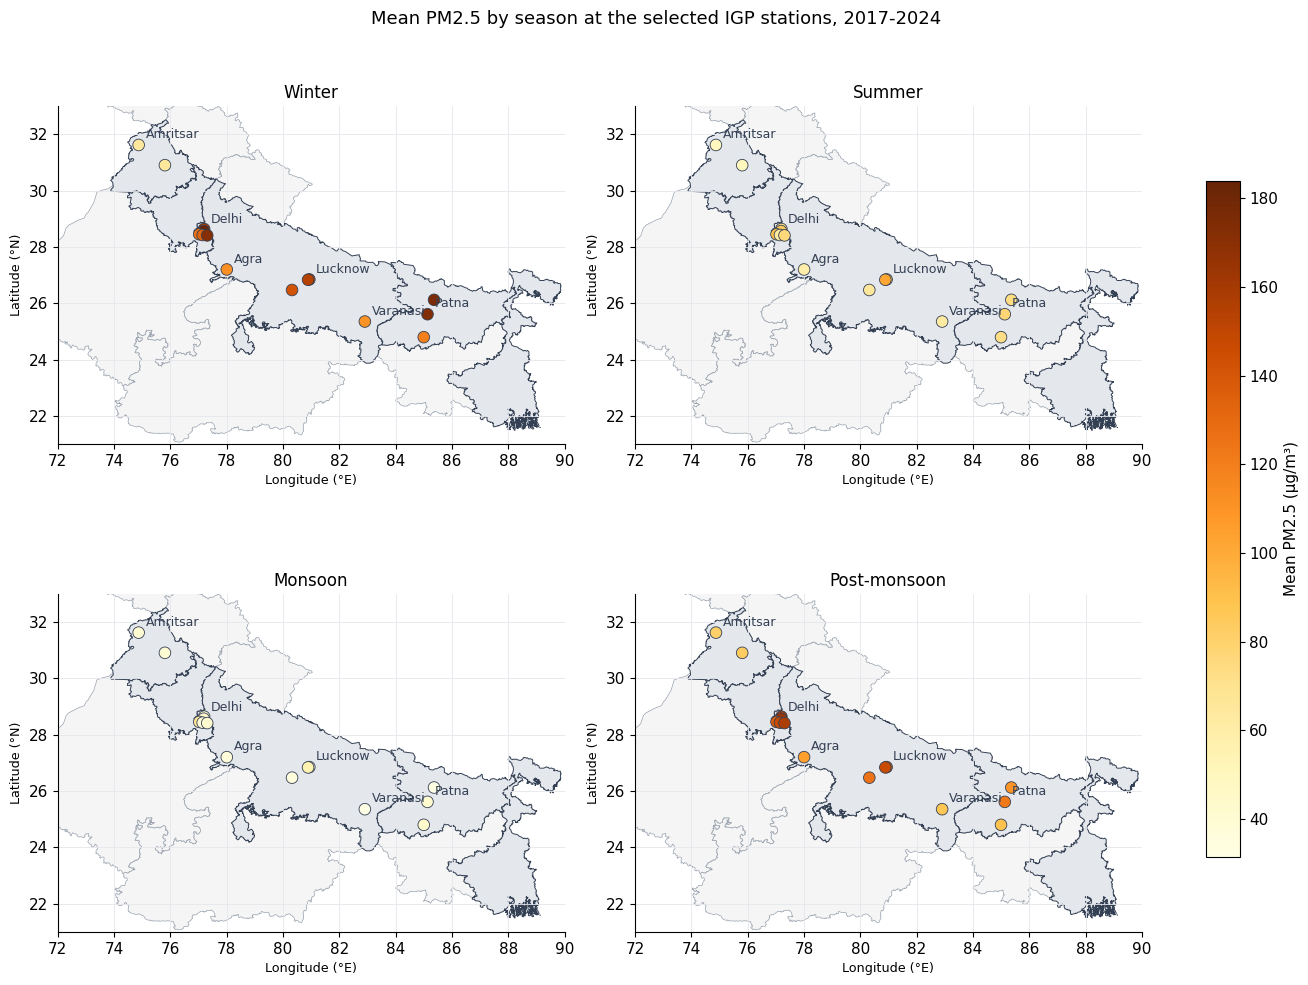

In [18]:
# Draw the 2x2 seasonal maps with one shared colour scale
seasons = ['Winter', 'Summer', 'Monsoon', 'Post-monsoon']
seasonmean = panel.groupby(['station', 'season'])['pm'].mean().unstack()
seasonmean = seasonmean.reindex(index=names, columns=seasons)
norm = Normalize(vmin=np.nanmin(seasonmean.values), vmax=np.nanmax(seasonmean.values))

fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, name in zip(axes.flat, seasons):
    drawmap(ax)
    ax.scatter(stations.loc[names, 'lon'], stations.loc[names, 'lat'], c=seasonmean[name],
               cmap='YlOrBr', norm=norm, s=70, edgecolor=slate, linewidth=0.6, zorder=3)
    labelmap(ax)
    ax.set_title(name)

scale = plt.cm.ScalarMappable(cmap='YlOrBr', norm=norm)
fig.colorbar(scale, ax=axes, shrink=0.7, label='Mean PM2.5 (µg/m³)')
fig.suptitle('Mean PM2.5 by season at the selected IGP stations, 2017-2024', fontsize=13)
plt.savefig(figdir + 'nb1-seasonal-maps.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** Winter and post-monsoon are much worse than the monsoon at every station, and in the monsoon all stations are low. Delhi, Lucknow and Patna are the most polluted in winter. The Punjab stations, inside the crop-burning region, are less polluted than the cities further down the plain.

## Step 11: Similarity and distance
All stations are worse in winter, so raw values would look similar even for stations far apart. So we first take the anomaly: each day's PM2.5 minus that station's average for that month. Then we correlate the anomalies of every pair of stations, separately for winter and monsoon.

In [19]:
# Anomaly = pm minus the station's average for that calendar month
monthmean = panel.groupby(['station', 'month'])['pm'].transform('mean')
panel['anom'] = panel['pm'] - monthmean

# Correlation of daily anomalies for every pair of stations, by season
pairrows = []
for name in ['Winter', 'Monsoon']:
    part = panel[panel['season'] == name].pivot(index='date', columns='station', values='anom')
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            first = part[names[i]]
            second = part[names[j]]
            both = first.notna() & second.notna()
            if both.sum() >= 100:
                rho = np.corrcoef(first[both], second[both])[0, 1]
                pairrows.append({'season': name, 'station1': names[i], 'station2': names[j],
                                 'dist': dist.loc[names[i], names[j]], 'rho': rho, 'days': int(both.sum())})
pairs = pd.DataFrame(pairrows)
print('Station pairs per season:')
print(pairs['season'].value_counts())
savecsv(pairs.round(4), figdir + 'nb1-pair-correlations.csv')

Station pairs per season:
season
Winter     105
Monsoon    105
Name: count, dtype: int64
Saved ../figures_outputs/nb1-pair-correlations.csv


Next we fit a distance-decay curve to these correlations for each season. It gives a starting level a and a decay length L in km. We expected a larger L in winter, because winter pollution should be shared over a wider area.

In [20]:
# Fit rho = a * exp(-d / L) for each season
def decay(d, a, length):
    return a * np.exp(-d / length)


fitrows = []
for name in ['Winter', 'Monsoon']:
    part = pairs[pairs['season'] == name]
    try:
        if len(part) < 5:
            raise ValueError('fewer than 5 station pairs')
        best, cov = curve_fit(decay, part['dist'].values, part['rho'].values,
                              p0=[0.8, 300], bounds=([0, 1], [1.5, 20000]), maxfev=10000)
        fitrows.append({'season': name, 'a': best[0], 'L': best[1], 'pairs': len(part)})
        print(name, ': a =', round(best[0], 3), ' L =', round(best[1], 1), 'km')
    except Exception as error:
        print('The fit failed for', name, ':', error)
        fitrows.append({'season': name, 'a': np.nan, 'L': np.nan, 'pairs': len(part)})
fits = pd.DataFrame(fitrows)
savecsv(fits.round(4), figdir + 'nb1-distance-decay.csv')
fits

Winter : a = 0.712  L = 765.8 km
Monsoon : a = 0.407  L = 1025.6 km
Saved ../figures_outputs/nb1-distance-decay.csv


,season,a,L,pairs
0,Winter,0.711607,765.774882,105
1,Monsoon,0.406671,1025.648386,105


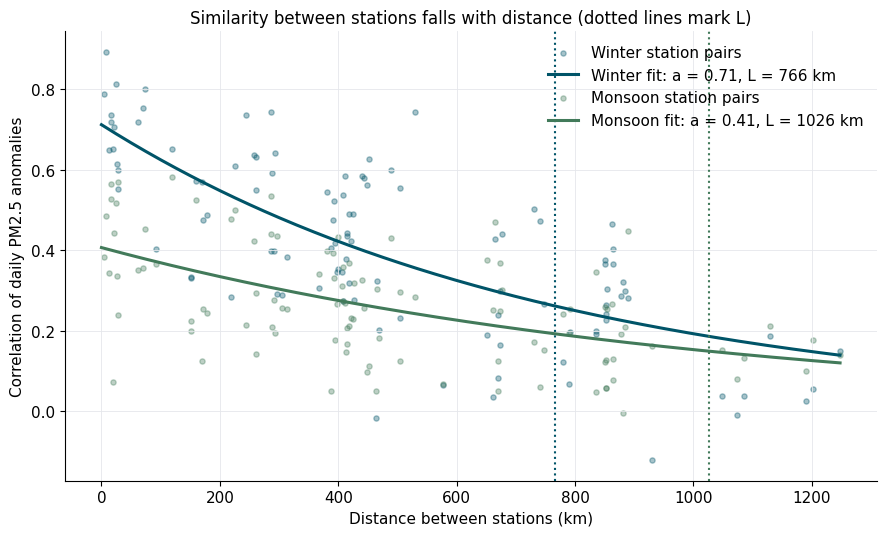

In [21]:
# Scatter of correlation versus distance with the fitted curves
colours = {'Winter': teal, 'Monsoon': green}
fig, ax = plt.subplots(figsize=(9, 5.5))
xs = np.linspace(0, pairs['dist'].max(), 300)
for name in ['Winter', 'Monsoon']:
    part = pairs[pairs['season'] == name]
    ax.scatter(part['dist'], part['rho'], color=colours[name], alpha=0.35, s=14, label=name + ' station pairs')
    row = fits[fits['season'] == name].iloc[0]
    if not np.isnan(row['L']):
        ax.plot(xs, decay(xs, row['a'], row['L']), color=colours[name], linewidth=2.2,
                label=f"{name} fit: a = {row['a']:.2f}, L = {row['L']:.0f} km")
        ax.axvline(row['L'], color=colours[name], linestyle=':', linewidth=1.5)
ax.set_xlabel('Distance between stations (km)')
ax.set_ylabel('Correlation of daily PM2.5 anomalies')
ax.set_title('Similarity between stations falls with distance (dotted lines mark L)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(figdir + 'nb1-distance-decay.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The winter fit gives a = 0.71 and L = 766 km, and the monsoon fit gives a = 0.41 and L = 1026 km. Winter similarity is much higher at every distance, so winter pollution is more shared. The monsoon L is larger, which is the opposite of what we expected, but the monsoon curve starts low and is almost flat, so its L means little and the level of the curve tells the story better.

## Step 12: Does pollution move from Delhi?
In winter the wind often blows from the north-west to the south-east. If smoke travels with it, a bad day in Delhi should be followed a day or two later by a bad day further east. We check this by correlating Delhi's winter anomaly with each city's anomaly 0 to 3 days later.

In [22]:
# Lead-lag correlation between Delhi and every other city in winter
cityanom = panel.groupby(['date', 'city'])['anom'].mean().unstack('city')
cityanom = cityanom.reindex(alldays)
winterdays = cityanom.index.month.isin([11, 12, 1, 2])
lags = [0, 1, 2, 3]
simcols = ['sim0', 'sim1', 'sim2', 'sim3']

waverows = []
if 'Delhi' not in cityanom.columns:
    print('Delhi is not among the selected cities, so the pollution-wave test is skipped.')
else:
    delhi = cityanom['Delhi']
    for city in cityanom.columns:
        if city == 'Delhi':
            continue
        row = {'city': city,
               'distkm': haversine(centres.loc['Delhi', 'lat'], centres.loc['Delhi', 'lon'],
                                   centres.loc[city, 'lat'], centres.loc[city, 'lon'])}
        for k in lags:
            later = cityanom[city].shift(-k)   # value of the city k days later
            both = winterdays & delhi.notna().values & later.notna().values
            if both.sum() >= 30:
                row['sim' + str(k)] = np.corrcoef(delhi[both], later[both])[0, 1]
            else:
                row['sim' + str(k)] = np.nan
        waverows.append(row)

wave = pd.DataFrame(waverows)
if len(wave) > 0:
    peaklags = []
    peaksims = []
    for i in range(len(wave)):
        values = wave.loc[i, simcols].astype(float)
        if values.notna().any():
            top = values.idxmax()
            peaklags.append(int(top.replace('sim', '')))
            peaksims.append(values[top])
        else:
            peaklags.append(np.nan)
            peaksims.append(np.nan)
    wave['bestk'] = peaklags
    wave['bestsim'] = peaksims
    wave = wave.sort_values('distkm').reset_index(drop=True)
    savecsv(wave.round(3), figdir + 'nb1-pollution-wave.csv')
wave

Saved ../figures_outputs/nb1-pollution-wave.csv


,city,distkm,sim0,sim1,sim2,sim3,bestk,bestsim
0,Gurugram,20.936066,0.794103,0.552087,0.295968,0.184283,0,0.794103
1,Faridabad,24.069769,0.685838,0.455959,0.211795,0.118889,0,0.685838
2,Agra,175.047496,0.466530,0.380005,0.242499,0.152716,0,0.466530
3,Ludhiana,288.890680,0.440765,0.284085,0.181371,0.149952,0,0.440765
4,Kanpur,388.881257,0.365943,0.332904,0.202797,0.092890,0,0.365943
5,Amritsar,403.048435,0.400151,0.272829,0.150299,0.101107,0,0.400151
6,Lucknow,415.160680,0.434550,0.432812,0.296998,0.179654,0,0.434550
7,Varanasi,671.560710,0.218057,0.208839,0.166171,0.117753,0,0.218057
8,Muzaffarpur,852.443375,0.166850,0.153632,0.119819,0.058163,0,0.166850
9,Patna,852.932764,0.200967,0.202033,0.163377,0.071835,1,0.202033


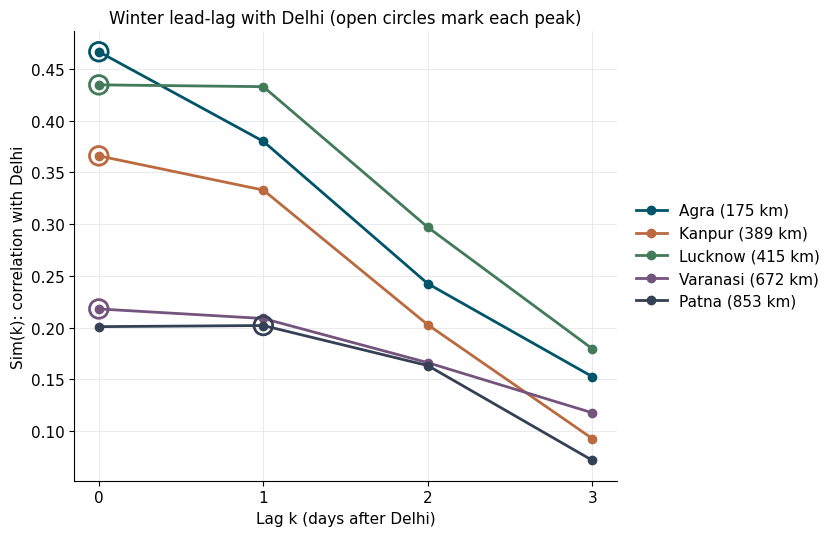

In [23]:
# Plot Sim(k) for a few cities at increasing distance from Delhi
if len(wave) == 0:
    print('Nothing to plot.')
else:
    pick = []
    for city in ['Agra', 'Kanpur', 'Lucknow', 'Varanasi', 'Patna']:
        if city in list(wave['city']):
            pick.append(city)
    if len(pick) < 3:
        pick = list(wave['city'].head(5))
    linecolours = [teal, orange, green, plum, slate]

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    for city, colour in zip(pick, linecolours):
        row = wave[wave['city'] == city].iloc[0]
        sims = row[simcols].astype(float).values
        ax.plot(lags, sims, marker='o', color=colour, linewidth=2,
                label=f"{city} ({row['distkm']:.0f} km)")
        if not np.isnan(row['bestk']):
            ax.scatter([row['bestk']], [row['bestsim']], s=180, facecolor='none', edgecolor=colour, linewidth=2, zorder=4)
    ax.set_xticks(lags)
    ax.set_xlabel('Lag k (days after Delhi)')
    ax.set_ylabel('Sim(k): correlation with Delhi')
    ax.set_title('Winter lead-lag with Delhi (open circles mark each peak)')
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    plt.savefig(figdir + 'nb1-pollution-wave.png', dpi=300, bbox_inches='tight')
    plt.show()

**Observation:** Agra, Kanpur, Lucknow and Varanasi match Delhi best on the same day (k = 0). Only Patna peaks at k = 1, and only by a tiny margin (0.202 vs 0.201). So the cities mostly rise and fall together on the same day, not as a clear wave from Delhi, and shared winter weather over the whole plain seems to matter more than smoke travelling from day to day.

## Step 13: Airsheds with k-means
An airshed is a group of places that share the same air. We give k-means one row per station with its daily anomalies, standardised per station so that very polluted stations do not dominate. We try 2 to 8 groups and pick the number with the best silhouette score.

In [ ]:
# Build the station x day matrix of standardised anomalies
zwide = panel.pivot(index='date', columns='station', values='anom')[names]
zwide = (zwide - zwide.mean()) / zwide.std()
zwide = zwide.fillna(0)
matrix = zwide.T.values
print('Matrix size (stations x days):', matrix.shape)

# Try K = 2 to 8 and keep the silhouette score of each
maxk = min(8, len(names) - 1)
silrows = []
for k in range(2, maxk + 1):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(matrix)
    silrows.append({'K': k, 'silhouette': silhouette_score(matrix, labels)})
sil = pd.DataFrame(silrows)
bestk = int(sil.loc[sil['silhouette'].idxmax(), 'K'])
print('Best K:', bestk)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sil['K'], sil['silhouette'], marker='o', color=teal, linewidth=2)
ax.axvline(bestk, color=orange, linestyle='--', label='Best K = ' + str(bestk))
ax.set_xlabel('Number of clusters K')
ax.set_ylabel('Silhouette score')
ax.set_title('Choosing the number of airsheds')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(figdir + 'nb1-silhouette.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The best K is 3, but the silhouette score is low (about 0.15), so the groups are only weakly separated. This is what we expected with only 15 stations.

Saved ../figures_outputs/nb1-airsheds.csv


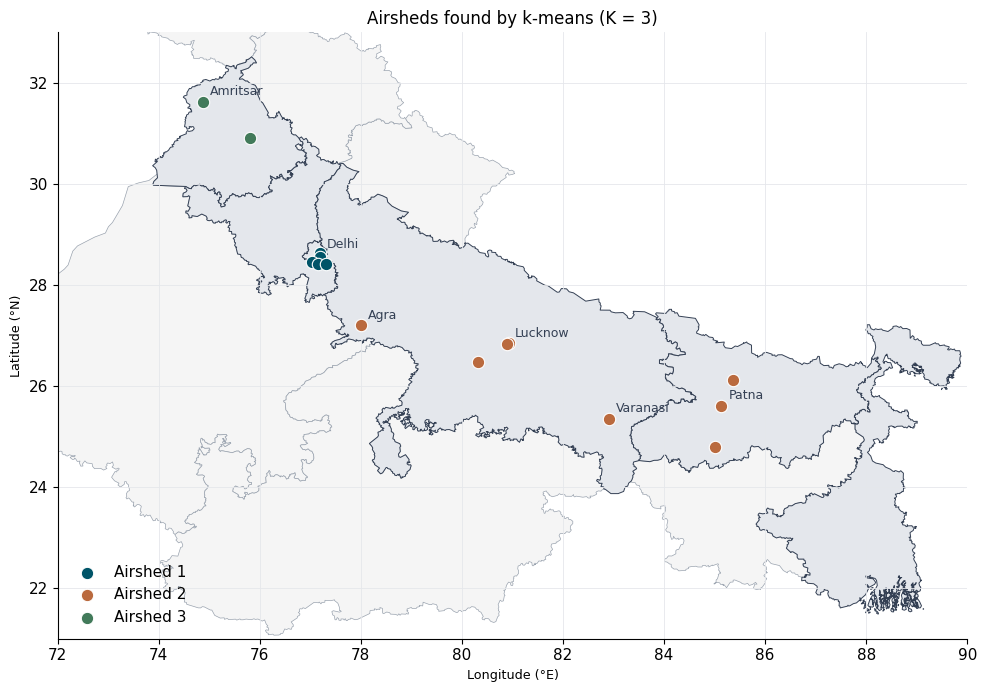

cluster
1                         [Delhi, Gurugram, Faridabad]
2    [Agra, Kanpur, Lucknow, Varanasi, Patna, Gaya,...
3                                 [Amritsar, Ludhiana]
Name: city, dtype: object

In [25]:
# Final k-means with the best K, then map the stations coloured by cluster
model = KMeans(n_clusters=bestk, n_init=10, random_state=42)
clusters = model.fit_predict(matrix) + 1   # number clusters from 1
airsheds = stations[['city', 'state', 'lat', 'lon']].reset_index()
airsheds['cluster'] = clusters
savecsv(airsheds, figdir + 'nb1-airsheds.csv')

clustercolours = [teal, orange, green, plum, slate, grey, '#B08D57', '#5B7DA8']
fig, ax = plt.subplots(figsize=(10, 7))
drawmap(ax)
for c in range(1, bestk + 1):
    part = airsheds[airsheds['cluster'] == c]
    ax.scatter(part['lon'], part['lat'], s=80, color=clustercolours[c - 1], edgecolor='white',
               linewidth=0.8, zorder=3, label='Airshed ' + str(c))
labelmap(ax)
ax.set_title('Airsheds found by k-means (K = ' + str(bestk) + ')')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(figdir + 'nb1-airshed-map.png', dpi=300, bbox_inches='tight')
plt.show()
airsheds.groupby('cluster')['city'].unique()

**Observation:** The three groups follow geography: Punjab (Amritsar, Ludhiana), the Delhi region (Delhi, Gurugram, Faridabad), and Uttar Pradesh together with Bihar.

## Step 14: Saving the station-day table
We save the final table to data/processed/panel.csv. Notebooks 2 and 3 start from this file.

In [26]:
# Add the cluster and save the station-day table
panel = panel.merge(airsheds[['station', 'cluster']], on='station', how='left')
columns = ['date', 'station', 'city', 'state', 'lat', 'lon', 'pm', 'temp', 'humidity',
           'wind', 'winddir', 'rain', 'nbravg', 'cluster']
if 'humidity' not in panel.columns:
    columns.remove('humidity')
savecsv(panel[columns], panelpath)
print('Rows:', len(panel), '  Stations:', panel['station'].nunique(), '  Columns:', columns)

Saved ../data/processed/panel.csv
Rows: 43830   Stations: 15   Columns: ['date', 'station', 'city', 'state', 'lat', 'lon', 'pm', 'temp', 'humidity', 'wind', 'winddir', 'rain', 'nbravg', 'cluster']


## Summary
In this notebook we cleaned the CPCB data and picked 15 stations in 12 cities from Punjab to Bihar, each with daily weather and a neighbour average. Winter and post-monsoon are much worse than the monsoon everywhere, and in winter the stations are much more alike, even when they are far apart. The cities mostly rise and fall on the same day rather than as a wave from Delhi, so shared winter weather seems to matter more than smoke moving across the plain. K-means found three weak but clearly geographic airsheds: Punjab, the Delhi region, and Uttar Pradesh with Bihar. In the next notebook we use this table to test whether next-day PM2.5 can be forecast (RQ1).